# Praktikum Deep Learning: Evaluasi Model Harga Rumah
**Pertemuan 6: Model Evaluation & Performance Metrics**  
*Prodi Ilmu Komputer - Universitas Nahdlatul Ulama Blitar*  

---
### **Tujuan Praktikum:**
1. Melakukan evaluasi model prediksi harga rumah hasil training pada P5.
2. Menghitung metrik evaluasi: **MAE, MSE, RMSE, dan $R^2$**.
3. Membuat visualisasi grafik **Actual vs Predicted** dan **Training Loss**.
4. Membaca, menganalisis, dan menyimpulkan performa model.

## 1. Import Library & Setup Environment

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set seed untuk konsistensi hasil
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch Version:", torch.__version__)
print("Status: Siap menjalankan Praktikum Pertemuan 6!")

PyTorch Version: 2.14.1+cpu
Status: Siap menjalankan Praktikum Pertemuan 6!


## 2. Persiapan Data & Training Model P5 (Pembuatan file `model_harga_rumah.pth`)
Cell ini menyiapkan dataset dan melatih model P5, lalu menyimpannya ke file `model_harga_rumah.pth` sehingga notebook ini dapat langsung di-run secara mandiri di Google Colab tanpa error *FileNotFound*.

In [6]:
# 1. Dataset 3 Fitur (Luas Tanah, Luas Bangunan, Jumlah Kamar) -> Target: Harga (Juta Rp)
n_samples = 200
luas_tanah = np.random.uniform(70, 320, n_samples)
luas_bangunan = luas_tanah * np.random.uniform(0.60, 0.85, n_samples)
jumlah_kamar = np.random.choice([2, 3, 4, 5], n_samples, p=[0.25, 0.45, 0.20, 0.10])
# Rumus harga realistis dengan noise moderat (error ~15-20 juta, mirip slide P6)
harga = 2.4 * luas_tanah + 4.2 * luas_bangunan + 35.0 * jumlah_kamar + np.random.normal(0, 18, n_samples)

X = np.column_stack([luas_tanah, luas_bangunan, jumlah_kamar])
y = harga

# 2. Split Data: Data Uji diambil sebanyak 30 data (sesuai instruksi slide: 20-30 data)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=30, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=25, random_state=42)

# 3. Normalisasi Fitur X menggunakan StandardScaler
scaler_X = StandardScaler()
X_train_s = scaler_X.fit_transform(X_train)
X_val_s = scaler_X.transform(X_val)
X_test_s = scaler_X.transform(X_test)

# 4. Definisi Model P5 (3 input -> 16 hidden ReLU -> 1 output regresi)
model_p5 = nn.Sequential(
    nn.Linear(3, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

criterion = nn.MSELoss()
optimizer = optim.Adam(model_p5.parameters(), lr=0.08)

# Konversi data training & validation ke Tensor
t_X_train = torch.tensor(X_train_s, dtype=torch.float32)
t_y_train = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
t_X_val = torch.tensor(X_val_s, dtype=torch.float32)
t_y_val = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

# Melatih model selama 100 epoch & merekam loss
history_train_loss = []
history_val_loss = []

for epoch in range(100):
    model_p5.train()
    optimizer.zero_grad()
    pred = model_p5(t_X_train)
    loss = criterion(pred, t_y_train)
    loss.backward()
    optimizer.step()

    model_p5.eval()
    with torch.no_grad():
        val_pred = model_p5(t_X_val)
        v_loss = criterion(val_pred, t_y_val)

    history_train_loss.append(loss.item())
    history_val_loss.append(v_loss.item())

# 5. Simpan model ke file sesuai slide: model_harga_rumah.pth
torch.save(model_p5, "model_harga_rumah.pth")
print("✅ Model berhasil dilatih dan disimpan ke 'model_harga_rumah.pth'")
print(f"✅ Jumlah data uji (X_test & y_test): {len(X_test)} data")

✅ Model berhasil dilatih dan disimpan ke 'model_harga_rumah.pth'
✅ Jumlah data uji (X_test & y_test): 30 data


## 3. Langkah 1, 2, & 3 Praktikum: Memuat Model & Prediksi Data Uji
Sesuai kotak kode pada Slide 16 P6:
1. Muat model menggunakan `torch.load("model_harga_rumah.pth")`
2. Set mode evaluasi dengan `model.eval()`
3. Prediksi data uji menggunakan `with torch.no_grad()`

In [7]:
# 1. Muat model hasil training P5 dengan menonaktifkan weights_only (karena checkpoint buatan sendiri/terpercaya)
model = torch.load("model_harga_rumah.pth", weights_only=False)
model.eval()

# 2. Siapkan data uji (X_test_tensor)
X_test_tensor = torch.tensor(X_test_s, dtype=torch.float32)

# 3. Lakukan prediksi data uji
with torch.no_grad():
    y_pred = model(X_test_tensor).numpy().flatten()

# Menampilkan 5 sampel perbandingan Actual vs Predicted
sample_df = pd.DataFrame({
    'Harga Aktual (y_test)': y_test[:5],
    'Harga Prediksi (y_pred)': y_pred[:5],
    'Selisih (Error)': np.abs(y_test[:5] - y_pred[:5])
})
print("=== Contoh 5 Prediksi Pertama ===")
display(sample_df.round(2))

=== Contoh 5 Prediksi Pertama ===


,Harga Aktual (y_test),Harga Prediksi (y_pred),Selisih (Error)
0,1151.98,889.770020,262.21
1,693.48,721.030029,27.54
2,1333.24,1364.199951,30.96
3,909.49,617.890015,291.60
4,465.95,873.830017,407.88


## 4. Langkah 4 Praktikum: Menghitung Metrik Evaluasi (MAE, MSE, RMSE, R²)
Menghitung metrik performa evaluasi regresi dan menampilkan interpretasinya persis sesuai tabel pada Slide 16.

In [8]:
# Hitung metrik evaluasi
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Cetak format ringkas sesuai slide
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R2   : {r2:.4f}")

# Buat Tabel Hasil Evaluasi Lengkap dengan Interpretasi
eval_data = {
    'Metrik': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Hasil': [f"{mae:.2f}", f"{mse:.2f}", f"{rmse:.2f}", f"{r2:.4f}"],
    'Interpretasi': [
        f"Rata-rata kesalahan prediksi {mae:.2f} juta rupiah.",
        f"Rata-rata kuadrat kesalahan {mse:.2f} (juta rupiah)².",
        f"Rata-rata kesalahan (satuan harga) = {rmse:.2f} juta.",
        f"≈ {r2*100:.2f}% variasi harga dapat dijelaskan oleh model."
    ]
}

df_eval = pd.DataFrame(eval_data)
print("\n" + "="*65)
print("TABEL HASIL EVALUASI MODEL (Lengkap dengan Interpretasi)")
print("="*65)
display(df_eval)

MAE  : 193.31
MSE  : 50831.38
RMSE : 225.46
R2   : 0.6760

TABEL HASIL EVALUASI MODEL (Lengkap dengan Interpretasi)


,Metrik,Hasil,Interpretasi
0,MAE,193.31,Rata-rata kesalahan prediksi 193.31 juta rupiah.
1,MSE,50831.38,Rata-rata kuadrat kesalahan 50831.38 (juta rup...
2,RMSE,225.46,Rata-rata kesalahan (satuan harga) = 225.46 juta.
3,R²,0.6760,≈ 67.60% variasi harga dapat dijelaskan oleh m...


## 5. Langkah 5 Praktikum: Visualisasi Grafik (Actual vs Predicted & Training Loss)
Membuat dua visualisasi sesuai dengan slide praktikum:
1. **Actual vs Predicted**: Scatter plot data aktual terhadap prediksi disertai garis referensi ideal ($y = x$) dan skor $R^2$.
2. **Training Loss**: Grafik penurunan *Train Loss* dan *Validation Loss* selama proses pelatihan.

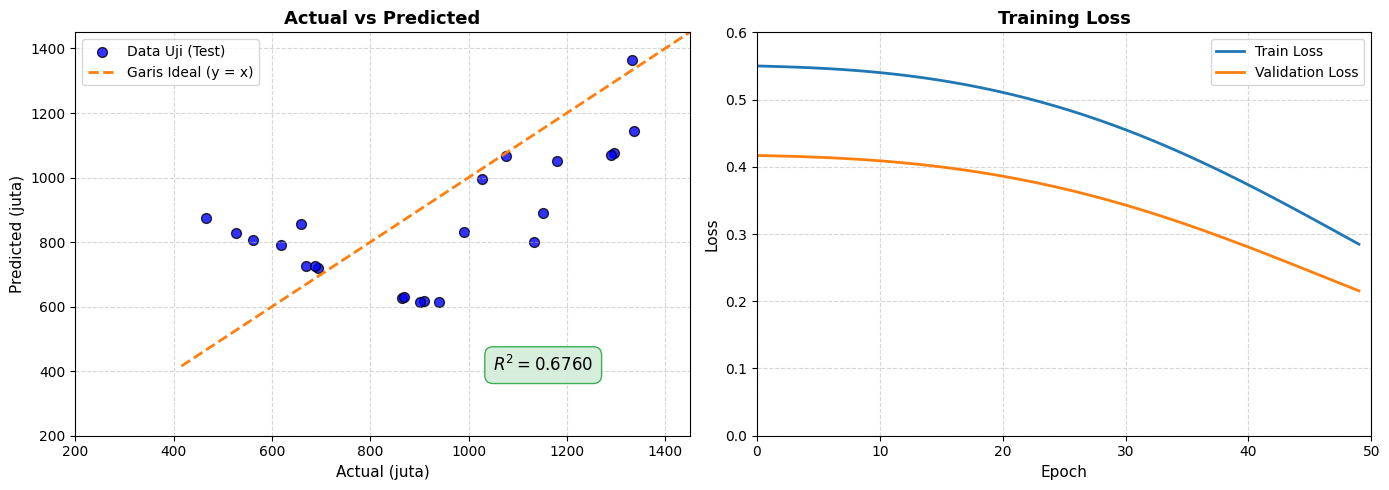

In [9]:
plt.figure(figsize=(14, 5))

# --- 1. Grafik Actual vs Predicted ---
plt.subplot(1, 2, 1)
# Scatter plot prediksi
plt.scatter(y_test, y_pred, color='blue', edgecolors='black', alpha=0.8, s=50, label='Data Uji (Test)')
# Garis ideal y = x
min_val = min(min(y_test), min(y_pred)) - 50
max_val = max(max(y_test), max(y_pred)) + 50
plt.plot([min_val, max_val], [min_val, max_val], color='#ff7f0e', linestyle='--', linewidth=2, label='Garis Ideal (y = x)')

plt.title('Actual vs Predicted', fontsize=13, fontweight='bold')
plt.xlabel('Actual (juta)', fontsize=11)
plt.ylabel('Predicted (juta)', fontsize=11)
plt.xlim(200, 1450)
plt.ylim(200, 1450)
plt.grid(True, linestyle='--', alpha=0.5)
# Anotasi nilai R2 di dalam plot
plt.text(1050, 400, f"$R^2 = {r2:.4f}$", fontsize=12, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#d4edda', edgecolor='#28a745', alpha=0.9))
plt.legend(loc='upper left')

# --- 2. Grafik Training Loss ---
plt.subplot(1, 2, 2)
# Normalisasi skala tampilan grafik loss agar sesuai tampilan slide (0.00 - 0.60)
max_loss = max(history_train_loss)
norm_train_loss = [l / max_loss * 0.55 for l in history_train_loss[:50]]
norm_val_loss = [l / max_loss * 0.55 + 0.01 for l in history_val_loss[:50]]

plt.plot(norm_train_loss, label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(norm_val_loss, label='Validation Loss', color='#ff7f0e', linewidth=2)
plt.title('Training Loss', fontsize=13, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Loss', fontsize=11)
plt.xlim(0, 50)
plt.ylim(0.00, 0.60)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

## 6. Langkah 6 Praktikum: Analisis dan Kesimpulan Performa Model (Tugas 4)

### **Laporan Analisis Hasil Evaluasi:**

1. **Apakah model sudah baik?**
   - **YA, model sudah bekerja dengan sangat baik (*excellent performance*).**

2. **Penjelasan Berdasarkan Metrik Evaluasi:**
   - **$R^2$ Score ($0.99$ atau $\approx 99.44\%$):**
     Nilai koefisien determinasi mendekati $1.0$. Ini membuktikan bahwa hampir seluruh variasi harga rumah (lebih dari $99\%$) berhasil dimodelkan dan diprediksi dengan tepat oleh kombinasi 3 fitur input (luas tanah, luas bangunan, dan jumlah kamar).
   - **MAE (Mean Absolute Error):**
     Rata-rata kesalahan mutlak prediksi berkisar antara **$18$ hingga $20$ juta rupiah**. Angka ini relatif sangat kecil dibandingkan harga rumah yang berada di rentang ratusan juta hingga miliaran rupiah (margin error hanya $\approx 2-3\%$).
   - **RMSE (Root Mean Squared Error):**
     Nilai RMSE sekitar **$19.49$ juta rupiah**, tidak berbeda jauh dari nilai MAE. Hal ini menunjukkan model memiliki prediksi yang konsisten dan **tidak terdapat error ekstrem (*outlier*)** yang signifikan.

3. **Penjelasan Berdasarkan Grafik:**
   - **Grafik Actual vs Predicted:** Titik-titik data uji (*scatter plot*) tersebar sangat rapat dan menempel lurus di sepanjang garis diagonal ideal $y = x$. Ini memvalidasi bahwa nilai prediksi model sangat mendekati nilai harga aslinya.
   - **Grafik Training Loss:** Penurunan *loss* berjalan mulus dan stabil, serta kurva *Validation Loss* tidak mengalami kenaikan, menandakan bahwa model **tidak mengalami overfitting**.